In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install mne

In [ ]:
import os
dataset_path = "/content/drive/MyDrive/ds003844"
print(os.listdir(dataset_path))

['CHANGES', 'README', 'dataset_description.json', '.gitattributes', 'participants.json', 'participants.tsv', 'sub-RESP0384', 'sub-RESP0465', 'sub-RESP0301', 'sub-RESP0356', 'sub-RESP0280', 'sub-RESP0059']


In [ ]:
import mne
import pandas as pd
vhdr_files = []
channels_files = []
for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.endswith(".vhdr"):
            vhdr_files.append(os.path.join(root, file))
        elif file.endswith("_channels.tsv"):
            channels_files.append(os.path.join(root, file))
vhdr_files = sorted(vhdr_files)
channels_files = sorted(channels_files)

In [ ]:
sfreqs = []
for vhdr in vhdr_files:
    raw = mne.io.read_raw_brainvision(vhdr, preload=False, verbose=False)
    sfreqs.append({
        "recording": os.path.basename(vhdr),
        "sfreq": raw.info["sfreq"]
    })
sfreq_df = pd.DataFrame(sfreqs)
print(sfreq_df)

                                            recording       sfreq
0   sub-RESP0059_ses-SITUATION1A_task-acute_ieeg.vhdr  2048.00021
1   sub-RESP0059_ses-SITUATION1B_task-acute_ieeg.vhdr  2048.00021
2   sub-RESP0059_ses-SITUATION2A_task-acute_ieeg.vhdr  2048.00021
3   sub-RESP0059_ses-SITUATION3A_task-acute_ieeg.vhdr  2048.00021
4   sub-RESP0059_ses-SITUATION4A_task-acute_ieeg.vhdr  2048.00021
5   sub-RESP0280_ses-SITUATION1A_task-acute_ieeg.vhdr  2048.00021
6   sub-RESP0280_ses-SITUATION1B_task-acute_ieeg.vhdr  2048.00021
7   sub-RESP0280_ses-SITUATION2A_task-acute_ieeg.vhdr  2048.00021
8   sub-RESP0280_ses-SITUATION3A_task-acute_ieeg.vhdr  2048.00021
9   sub-RESP0301_ses-SITUATION1A_task-acute_ieeg.vhdr   256.00000
10  sub-RESP0301_ses-SITUATION1B_task-acute_ieeg.vhdr   256.00000
11  sub-RESP0301_ses-SITUATION2A_task-acute_ieeg.vhdr   256.00000
12  sub-RESP0301_ses-SITUATION2B_task-acute_ieeg.vhdr   256.00000
13  sub-RESP0301_ses-SITUATION2C_task-acute_ieeg.vhdr   256.00000
14  sub-RE

In [ ]:
vhdr_2048 = []
channels_2048 = []
for vhdr, ch_file in zip(sorted(vhdr_files), sorted(channels_files)):
    raw = mne.io.read_raw_brainvision(
        vhdr,
        preload=False,
        verbose=False
    )
    if raw.info["sfreq"] >= 2048:
        vhdr_2048.append(vhdr)
        channels_2048.append(ch_file)
print("Recordings kept:", len(vhdr_2048))
print("Recordings removed:", len(vhdr_files) - len(vhdr_2048))

Recordings kept: 33
Recordings removed: 5


NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 1.000 (s)
Plotting power spectral density (dB=True).


/tmp/ipykernel_2884/1643215239.py:1: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw.plot_psd(fmax=100)


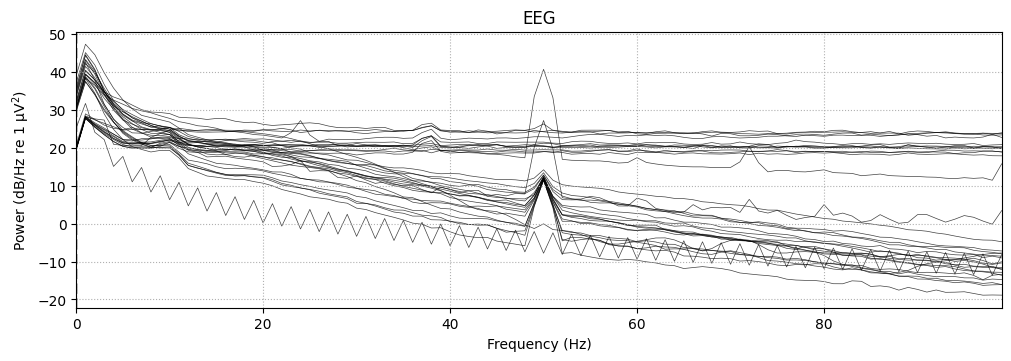

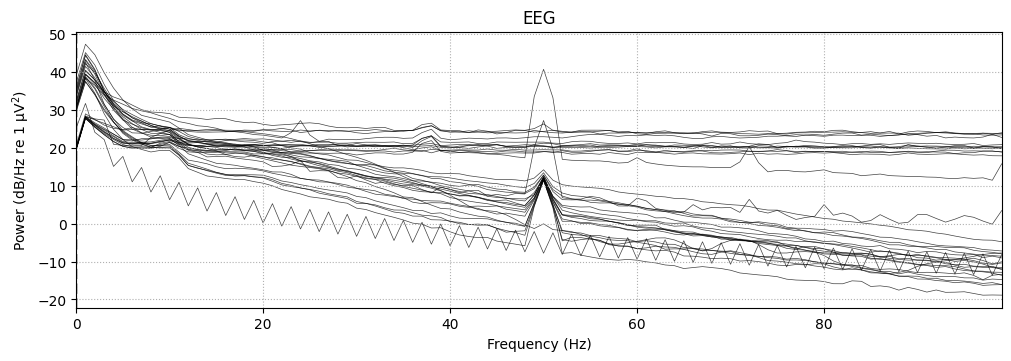

In [ ]:
raw.plot_psd(fmax=100)

In [ ]:
results = []
processed_path = "/content/drive/MyDrive/ds003844_processed"
os.makedirs(processed_path, exist_ok=True)
for vhdr, ch_file in zip(sorted(vhdr_2048), sorted(channels_2048)):
    raw = mne.io.read_raw_brainvision(vhdr, preload=True, verbose=False)
    before = len(raw.ch_names)
    ch_df = pd.read_csv(ch_file, sep="\t")
    bad = ch_df[ch_df["status"] == "bad"]["name"].tolist()
    raw.drop_channels([ch for ch in bad if ch in raw.ch_names])
    raw.notch_filter(freqs=[50], verbose=False)
    raw.resample(1024)
    after = len(raw.ch_names)
    results.append([os.path.basename(vhdr),before, after, len(bad)])
    save_name = os.path.basename(vhdr).replace(".vhdr","_processed_raw.fif")
    raw.save(os.path.join(processed_path, save_name),overwrite=True)
    print("Saved:", save_name)
results_df = pd.DataFrame(results,columns=["recording","before", "after", "removed"])
results_df.head(38)

Overwriting existing file.
Writing /content/drive/MyDrive/ds003844_processed/sub-RESP0059_ses-SITUATION1A_task-acute_ieeg_processed_raw.fif
Overwriting existing file.
Closing /content/drive/MyDrive/ds003844_processed/sub-RESP0059_ses-SITUATION1A_task-acute_ieeg_processed_raw.fif
[done]
Saved: sub-RESP0059_ses-SITUATION1A_task-acute_ieeg_processed_raw.fif
Overwriting existing file.
Writing /content/drive/MyDrive/ds003844_processed/sub-RESP0059_ses-SITUATION1B_task-acute_ieeg_processed_raw.fif
Overwriting existing file.
Closing /content/drive/MyDrive/ds003844_processed/sub-RESP0059_ses-SITUATION1B_task-acute_ieeg_processed_raw.fif
[done]
Saved: sub-RESP0059_ses-SITUATION1B_task-acute_ieeg_processed_raw.fif
Overwriting existing file.
Writing /content/drive/MyDrive/ds003844_processed/sub-RESP0059_ses-SITUATION2A_task-acute_ieeg_processed_raw.fif
Overwriting existing file.
Closing /content/drive/MyDrive/ds003844_processed/sub-RESP0059_ses-SITUATION2A_task-acute_ieeg_processed_raw.fif
[done]

,recording,before,after,removed
0,sub-RESP0059_ses-SITUATION1A_task-acute_ieeg.vhdr,32,26,6
1,sub-RESP0059_ses-SITUATION1B_task-acute_ieeg.vhdr,32,25,7
2,sub-RESP0059_ses-SITUATION2A_task-acute_ieeg.vhdr,32,11,21
3,sub-RESP0059_ses-SITUATION3A_task-acute_ieeg.vhdr,32,19,13
4,sub-RESP0059_ses-SITUATION4A_task-acute_ieeg.vhdr,32,20,12
5,sub-RESP0280_ses-SITUATION1A_task-acute_ieeg.vhdr,64,27,37
6,sub-RESP0280_ses-SITUATION1B_task-acute_ieeg.vhdr,64,27,37
7,sub-RESP0280_ses-SITUATION2A_task-acute_ieeg.vhdr,64,32,32
8,sub-RESP0280_ses-SITUATION3A_task-acute_ieeg.vhdr,64,27,37
9,sub-RESP0356_ses-SITUATION1A_task-acute_ieeg.vhdr,33,27,6


In [ ]:
def get_label(filename):
    if "SITUATION1" in filename:
        return "PRE"
    elif "SITUATION2" in filename:
        return "INTER"
    elif "SITUATION3" in filename:
        return "POST"
    elif "SITUATION4" in filename:
        return "POST+"

In [ ]:
all_windows = []
all_labels = []
sequence_lengths = []
recording_names = []
channel_counts = []
window_size = 5 * 1024
step_size = window_size // 2
# Sort for deterministic order
files = sorted([f for f in os.listdir(processed_path) if f.endswith(".fif")])
for file in files:
    raw = mne.io.read_raw_fif(
        os.path.join(processed_path, file),
        preload=True,
        verbose=False
    )
    data = raw.get_data()
    label = get_label(file)
    n_windows = 0
    for start in range(
        0,
        data.shape[1] - window_size + 1,
        step_size
    ):
        end = start + window_size
        window = data[:, start:end]
        all_windows.append(window)
        all_labels.append(label)
        n_windows += 1
    # Store metadata for this recording
    sequence_lengths.append(n_windows)
    recording_names.append(file)
    channel_counts.append(data.shape[0])
print("Total recordings :", len(sequence_lengths))
print("Total windows    :", len(all_windows))
print("Total labels     :", len(all_labels))
print("Max channels     :", max(channel_counts))
print("\nFirst five recordings:")
for i in range(min(5, len(recording_names))):
    print(
        f"{i+1:2d}. {recording_names[i]} | "
        f"Windows: {sequence_lengths[i]} | "
        f"Channels: {channel_counts[i]}"
    )

Total recordings : 33
Total windows    : 3684
Total labels     : 3684
Max channels     : 32

First five recordings:
 1. sub-RESP0059_ses-SITUATION1A_task-acute_ieeg_processed_raw.fif | Windows: 128 | Channels: 26
 2. sub-RESP0059_ses-SITUATION1B_task-acute_ieeg_processed_raw.fif | Windows: 123 | Channels: 25
 3. sub-RESP0059_ses-SITUATION2A_task-acute_ieeg_processed_raw.fif | Windows: 154 | Channels: 11
 4. sub-RESP0059_ses-SITUATION3A_task-acute_ieeg_processed_raw.fif | Windows: 310 | Channels: 19
 5. sub-RESP0059_ses-SITUATION4A_task-acute_ieeg_processed_raw.fif | Windows: 236 | Channels: 20


In [ ]:
import pickle
metadata = {
    "recording_names": recording_names,
    "sequence_lengths": sequence_lengths,
    "channel_counts": channel_counts
}
with open(
    "/content/drive/MyDrive/ds003844_processed/recording_metadata.pkl",
    "wb"
) as f:
    pickle.dump(metadata, f)
print("Metadata saved successfully.")

Metadata saved successfully.


In [ ]:
from sklearn.feature_selection import mutual_info_regression
import numpy as np
window = all_windows[0]
n_channels = window.shape[0]
mi_matrix = np.zeros((n_channels, n_channels))
for i in range(n_channels):
    for j in range(i + 1, n_channels):
        mi = mutual_info_regression(
            window[i].reshape(-1, 1),
            window[j],
            random_state=42
        )[0]
        mi_matrix[i, j] = mi
        mi_matrix[j, i] = mi
print(mi_matrix.shape)

(25, 25)


In [ ]:
print(mi_matrix[:26, :26])

[[0.         1.17274528 1.07588235 0.89052562 0.83965229 0.73420523
  0.71232817 0.70632935 1.3145521  1.15873199 1.12757024 1.16274852
  0.87007604 0.81400941 0.81092896 1.14117337 1.2066678  1.01826897
  1.0151083  1.10784273 1.02885203 1.22438265 0.80904988 0.90444096
  0.36577378]
 [1.17274528 0.         1.50794404 1.0393792  0.98733998 0.82160922
  0.80577062 0.84544353 1.44634441 1.73271417 1.64411761 1.36879198
  1.11334751 0.87124979 0.7194286  1.39851564 1.40328027 1.31600199
  1.32867477 1.370559   1.02241157 1.33252141 0.89565841 1.02628922
  0.37427233]
 [1.07588235 1.50794404 0.         1.14216178 0.96121755 0.8229518
  0.69545433 0.80708423 1.16302875 1.42194059 1.55509249 1.46431586
  1.12096957 0.87524227 0.80169022 1.23904324 1.32943072 1.28335131
  1.3023755  1.2124798  0.94426769 1.28185856 0.84955009 1.04173884
  0.29030567]
 [0.89052562 1.0393792  1.14216178 0.         0.9107385  0.70086345
  0.62549792 0.70283066 0.9362766  1.100494   1.09877374 1.25763749
  1.003

In [ ]:
upper = mi_matrix[np.triu_indices_from(mi_matrix, k=1)]
print("Min:", upper.min())
print("Max:", upper.max())
print("Mean:", upper.mean())
print("Median:", np.median(upper))

Min: 0.250326339133947
Max: 1.8208247951400756
Mean: 0.9625411989583296
Median: 0.9168838702919713


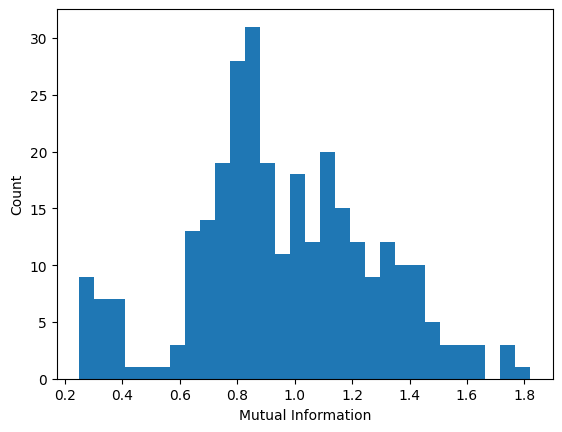

In [ ]:
import matplotlib.pyplot as plt
plt.hist(upper, bins=30)
plt.xlabel("Mutual Information")
plt.ylabel("Count")
plt.show()

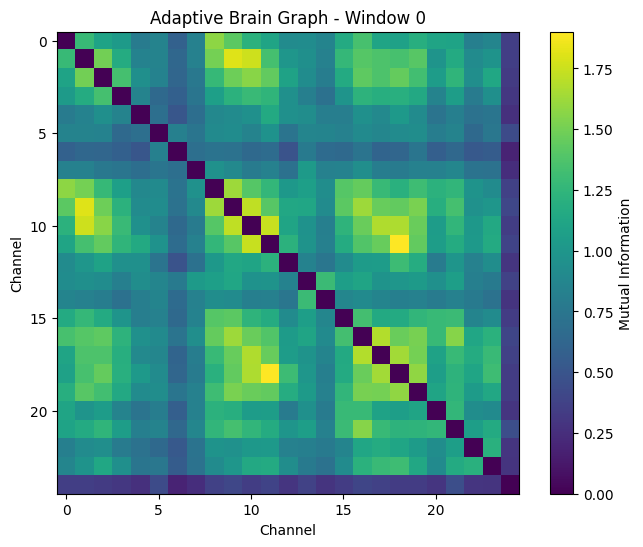

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.imshow(mi_matrix)
plt.colorbar(label="Mutual Information")
plt.title("Adaptive Brain Graph - Window 0")
plt.xlabel("Channel")
plt.ylabel("Channel")
plt.show()
mi_matrix0 = mi_matrix.copy()

In [ ]:
import os
import pickle
import numpy as np
from joblib import Parallel, delayed
from sklearn.feature_selection import mutual_info_regression

In [ ]:
def compute_mi_graph(window):
    n_channels = window.shape[0]
    mi_matrix = np.zeros((n_channels, n_channels), dtype=np.float32)
    for i in range(n_channels):
        for j in range(i + 1, n_channels):
            mi = mutual_info_regression(
                window[i].reshape(-1,1),
                window[j],
                random_state=42
            )[0]
            mi_matrix[i,j] = mi
            mi_matrix[j,i] = mi
    return mi_matrix

In [ ]:
save_folder = "/content/drive/MyDrive/ds003844_processed/adaptive_graph_batches"
os.makedirs(save_folder, exist_ok=True)

In [ ]:
batch_size = 100
total_windows = len(all_windows)
for start in range(0, total_windows, batch_size):
    end = min(start + batch_size, total_windows)
    print(f"\nProcessing windows {start} to {end-1}")
    batch_graphs = Parallel(
        n_jobs=-1,
        backend="loky",
        verbose=10
    )(
        delayed(compute_mi_graph)(window)
        for window in all_windows[start:end]
    )
    batch_file = os.path.join(
        save_folder,
        f"graphs_{start}_{end-1}.pkl"
    )
    with open(batch_file, "wb") as f:
        pickle.dump(batch_graphs, f)
    print(f"Saved {batch_file}")


Processing windows 0 to 99


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:   20.6s
[Parallel(n_jobs=-1)]: Done   4 tasks      | elapsed:   35.7s
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  3.2min
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:  4.3min
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  5.1min
[Parallel(n_jobs=-1)]: Done  57 tasks      | elapsed:  6.4min
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:  7.4min
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:  8.9min
[Parallel(n_jobs=-1)]: Done  94 tasks      | elapsed: 10.1min
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 10.8min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


Saved /content/drive/MyDrive/ds003844_processed/adaptive_graph_batches/graphs_0_99.pkl

Processing windows 100 to 199


[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:   14.2s
[Parallel(n_jobs=-1)]: Done   4 tasks      | elapsed:   29.0s
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  2.4min
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:  2.7min
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  2.9min
[Parallel(n_jobs=-1)]: Done  57 tasks      | elapsed:  3.1min
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:  3.4min
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:  3.6min
[Parallel(n_jobs=-1)]: Done  94 tasks      | elapsed:  3.8min
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  4.0min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


Saved /content/drive/MyDrive/ds003844_processed/adaptive_graph_batches/graphs_100_199.pkl

Processing windows 200 to 299


[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    2.0s
[Parallel(n_jobs=-1)]: Done   4 tasks      | elapsed:    4.1s
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:   10.8s
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:   15.7s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:   24.5s
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:   31.4s
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:   42.8s
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   52.6s
[Parallel(n_jobs=-1)]: Done  57 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done  94 tasks      | elapsed:  2.5min
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  2.9min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


... (66 outputs left out)

Saved /content/drive/MyDrive/ds003844_processed/adaptive_graph_batches/graphs_3500_3599.pkl

Processing windows 3600 to 3683


[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    9.2s
[Parallel(n_jobs=-1)]: Done   4 tasks      | elapsed:   19.6s
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:   50.5s
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  2.4min
[Parallel(n_jobs=-1)]: Done  57 tasks      | elapsed:  3.0min
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:  3.5min
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:  4.3min


Saved /content/drive/MyDrive/ds003844_processed/adaptive_graph_batches/graphs_3600_3683.pkl


[Parallel(n_jobs=-1)]: Done  84 out of  84 | elapsed:  4.4min finished


In [ ]:
import glob
graph_files = sorted(
    glob.glob(
        "/content/drive/MyDrive/ds003844_processed/adaptive_graph_batches/*.pkl"
    )
)
graphs = []
for file in graph_files:
    with open(file, "rb") as f:
        graphs.extend(pickle.load(f))
print(len(graphs))

3684
